# HW4 data overview

**Henri Mertens**

Inspect the classroom and full homework databases before building the
stock-return model and backtester. The checks cover file integrity,
table keys, date coverage, missing values and when information becomes
available. Queries use read-only database connections.

Run the cells from top to bottom with the HW4 Python environment.
The two databases should be in `Lectures/modeling/data/`.
Dependencies are DuckDB, pandas and Matplotlib.

The checks follow the instructor's
[modeling data guide](../../../Lectures/modeling/README.md) and
[HW4 instructions](../../../Lectures/Lecture%208/hw4.md).


In [1]:
import hashlib
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


working_directory = Path.cwd().resolve()
for candidate in [working_directory, *working_directory.parents]:
    manifest_path = candidate / "Lectures/modeling/data/manifest.json"
    if manifest_path.is_file():
        repository_root = candidate
        break
else:
    raise FileNotFoundError("Run this notebook inside the course repository.")

data_directory = repository_root / "Lectures/modeling/data"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
database_paths = {
    "Classroom": data_directory / "equities_class.duckdb",
    "Full homework": data_directory / "equities_top2000.duckdb",
}

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 12)
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)


def read_query(database_path, query):
    """Return a small query result using a read-only connection."""
    with duckdb.connect(str(database_path), read_only=True) as connection:
        return connection.execute(query).fetchdf()


file_records = []
original_checksums = {}
for dataset, database_path in database_paths.items():
    if not database_path.is_file():
        raise FileNotFoundError(f"Missing database: {database_path.name}")
    with database_path.open("rb") as database_file:
        checksum = hashlib.file_digest(database_file, "sha256").hexdigest()
    expected_file = manifest["files"][database_path.name]
    assert checksum == expected_file["sha256"]
    assert database_path.stat().st_size == expected_file["size_bytes"]
    original_checksums[dataset] = checksum
    file_records.append(
        {
            "Dataset": dataset,
            "File": database_path.name,
            "Size (MiB)": round(database_path.stat().st_size / 1024**2, 2),
            "Checksum matches": True,
        }
    )

display(pd.DataFrame(file_records))


,Dataset,File,Size (MiB),Checksum matches
0,Classroom,equities_class.duckdb,4.26,True
1,Full homework,equities_top2000.duckdb,314.76,True


## Tables and coverage

`prices` contains daily quotes, `fundamentals` contains financial reports,
and `universe_membership` records the stocks selected each quarter.
`benchmark` and `calendar` provide the comparison series and market sessions.
The remaining audit tables describe how quarterly membership was formed.

Compare row counts with the delivery manifest, then check the actual
first and last observations. The classroom extract is suitable for
development through 2015. Final evaluation needs the full database.


In [2]:
inventory_records = []
market_coverage_records = []
filing_coverage_records = []

for dataset, database_path in database_paths.items():
    expected_counts = manifest["files"][database_path.name]["rows"]
    with duckdb.connect(str(database_path), read_only=True) as connection:
        table_names = [row[0] for row in connection.execute("SHOW TABLES").fetchall()]
        assert set(expected_counts).issubset(table_names)
        for table_name in table_names:
            assert table_name.isidentifier()
            row_count = connection.execute(
                f'SELECT count(*) FROM "{table_name}"'
            ).fetchone()[0]
            expected_count = expected_counts.get(table_name)
            if expected_count is not None:
                assert row_count == expected_count
            inventory_records.append(
                {
                    "Dataset": dataset,
                    "Table": table_name,
                    "Rows": row_count,
                    "Manifest rows": expected_count,
                }
            )

    coverage = read_query(
        database_path,
        """
        SELECT
            min(date) AS first_price,
            max(date) AS last_price,
            count(DISTINCT symbol) AS stocks,
            count(*) AS price_rows,
            (SELECT count(*) FROM calendar) AS market_sessions
        FROM prices
        """,
    ).iloc[0]
    market_coverage_records.append({"Dataset": dataset, **coverage.to_dict()})

    filing_coverage = read_query(
        database_path,
        """
        SELECT
            min(fiscal_date) AS first_fiscal_date,
            max(fiscal_date) AS last_fiscal_date,
            min(filing_date) AS first_filing_date,
            max(filing_date) AS last_filing_date
        FROM fundamentals
        """,
    ).iloc[0]
    filing_coverage_records.append(
        {"Dataset": dataset, **filing_coverage.to_dict()}
    )

inventory = pd.DataFrame(inventory_records)
inventory["Manifest rows"] = inventory["Manifest rows"].astype("Int64")
market_coverage = pd.DataFrame(market_coverage_records)
filing_coverage = pd.DataFrame(filing_coverage_records)
display(inventory)
display(market_coverage)
display(filing_coverage)


,Dataset,Table,Rows,Manifest rows
0,Classroom,benchmark,2015,2015
1,Classroom,calendar,2015,2015
2,Classroom,dataset_metadata,9,<NA>
3,Classroom,dividends,110,110
4,Classroom,fundamentals,1059,1059
5,Classroom,prices,59286,59286
6,Classroom,universe,30,30
7,Classroom,universe_candidates,942,942
8,Classroom,universe_membership,937,937
9,Classroom,universe_rebalances,32,32


,Dataset,first_price,last_price,stocks,price_rows,market_sessions
0,Classroom,2008-01-02,2015-12-31,30,59286,2015
1,Full homework,2000-01-03,2026-09-30,3849,15839788,6726


,Dataset,first_fiscal_date,last_fiscal_date,first_filing_date,last_filing_date
0,Classroom,2007-01-31,2015-10-31,2007-03-27,2015-12-14
1,Full homework,2000-01-01,2026-09-30,2000-01-01,2026-09-30


## Required periods and table keys

The assignment separates development, a buffer for return targets to
finish, and the final test. Earlier observations can supply lookbacks.
A 90-day outcome becomes usable for fitting only after its actual exit.

The key checks count duplicate groups and missing key values in the
tables used for loading, features and trading dates.


In [3]:
assignment_periods = pd.DataFrame(
    [
        ["Development", "2010-01-01", "2015-12-31", "Model and strategy selection"],
        ["Buffer", "2016-01-01", "2016-03-31", "Earlier targets finish"],
        ["Final test", "2016-04-01", "2026-09-30", "Chosen strategy evaluation"],
    ],
    columns=["Period", "Start", "End", "Purpose"],
)
display(assignment_periods)

table_keys = {
    "prices": ["symbol", "date"],
    "fundamentals": ["symbol", "fiscal_date", "period"],
    "universe": ["symbol"],
    "universe_membership": ["symbol", "quarter_start"],
    "benchmark": ["date"],
    "calendar": ["date"],
}
key_records = []
for dataset, database_path in database_paths.items():
    for table_name, key_columns in table_keys.items():
        columns_sql = ", ".join(key_columns)
        null_condition = " OR ".join(
            f"{column_name} IS NULL" for column_name in key_columns
        )
        query = f"""
            SELECT
                (SELECT count(*) FROM (
                    SELECT {columns_sql}
                    FROM {table_name}
                    GROUP BY {columns_sql}
                    HAVING count(*) > 1
                )) AS duplicate_key_groups,
                (SELECT count(*) FROM {table_name}
                 WHERE {null_condition}) AS missing_key_rows
        """
        findings = read_query(database_path, query).iloc[0]
        key_records.append(
            {"Dataset": dataset, "Table": table_name, **findings.to_dict()}
        )

key_checks = pd.DataFrame(key_records)
display(key_checks)
assert key_checks["duplicate_key_groups"].eq(0).all()
assert key_checks["missing_key_rows"].eq(0).all()


,Period,Start,End,Purpose
0,Development,2010-01-01,2015-12-31,Model and strategy selection
1,Buffer,2016-01-01,2016-03-31,Earlier targets finish
2,Final test,2016-04-01,2026-09-30,Chosen strategy evaluation


,Dataset,Table,duplicate_key_groups,missing_key_rows
0,Classroom,prices,0,0
1,Classroom,fundamentals,0,0
2,Classroom,universe,0,0
3,Classroom,universe_membership,0,0
4,Classroom,benchmark,0,0
5,Classroom,calendar,0,0
6,Full homework,prices,0,0
7,Full homework,fundamentals,0,0
8,Full homework,universe,0,0
9,Full homework,universe_membership,0,0


## Price and financial-data quality

Reproduce the known delivery issues and compare their counts with the
manifest. Invalid adjusted prices and quotes outside the market calendar
need to be excluded from return calculations. Financial reports need
a valid filing date later than their fiscal end before they can become
feature inputs.

Missing-value percentages below concern raw financial fields. Any later
use of ratios still needs valid denominators and consistent units.


In [4]:
quality_records = []
missing_value_records = []
financial_columns = [
    "revenue", "net_income", "operating_income", "total_assets",
    "total_debt", "cash_and_equivalents", "free_cash_flow",
    "operating_cash_flow", "shares_outstanding", "market_cap",
]

for dataset, database_path in database_paths.items():
    findings = read_query(
        database_path,
        """
        SELECT
            (SELECT count(*) FROM prices
             WHERE adj_close IS NULL OR NOT isfinite(adj_close)
                OR adj_close <= 0) AS invalid_adjusted_price_rows,
            (SELECT count(*) FROM prices p
             WHERE NOT EXISTS (
                 SELECT 1 FROM calendar c WHERE c.date = p.date
             )) AS off_calendar_rows,
            (SELECT count(*) FROM fundamentals
             WHERE filing_date IS NULL OR fiscal_date IS NULL
                OR filing_date <= fiscal_date) AS invalid_filing_dates,
            (SELECT count(*) FROM fundamentals
             WHERE reported_currency IS NULL
                OR trim(reported_currency) = '') AS unknown_currency,
            (SELECT count(*) FROM fundamentals
             WHERE market_cap IS NULL) AS missing_market_cap
        """,
    ).iloc[0]
    specification = manifest["files"][database_path.name]
    expected_findings = {
        **specification["price_quality"],
        **specification["fundamental_quality"],
    }
    for metric_name, actual_count in findings.items():
        expected_count = expected_findings[metric_name]
        assert actual_count == expected_count
        quality_records.append(
            {
                "Dataset": dataset,
                "Issue": metric_name,
                "Observed": int(actual_count),
                "Manifest": expected_count,
            }
        )

    count_expressions = [
        f"count(*) FILTER (WHERE {column_name} IS NULL "
        f"OR NOT isfinite({column_name})) AS {column_name}"
        for column_name in financial_columns
    ]
    missing_counts = read_query(
        database_path,
        "SELECT " + ", ".join(count_expressions) + " FROM fundamentals",
    ).iloc[0]
    financial_row_count = specification["rows"]["fundamentals"]
    for column_name, missing_count in missing_counts.items():
        missing_value_records.append(
            {
                "Dataset": dataset,
                "Field": column_name,
                "Missing or nonfinite": int(missing_count),
                "Missing (%)": round(100 * missing_count / financial_row_count, 2),
            }
        )

quality_summary = pd.DataFrame(quality_records)
missing_values = pd.DataFrame(missing_value_records)
display(quality_summary)
display(missing_values)

full_database = database_paths["Full homework"]
invalid_price_examples = read_query(
    full_database,
    """
    SELECT symbol, min(date) AS first_date, max(date) AS last_date,
           count(*) AS invalid_rows
    FROM prices
    WHERE adj_close IS NULL OR NOT isfinite(adj_close) OR adj_close <= 0
    GROUP BY symbol
    ORDER BY symbol
    """,
)
display(invalid_price_examples)


,Dataset,Issue,Observed,Manifest
0,Classroom,invalid_adjusted_price_rows,0,0
1,Classroom,off_calendar_rows,0,0
2,Classroom,invalid_filing_dates,14,14
3,Classroom,unknown_currency,1058,1058
4,Classroom,missing_market_cap,981,981
5,Full homework,invalid_adjusted_price_rows,275,275
6,Full homework,off_calendar_rows,28,28
7,Full homework,invalid_filing_dates,23664,23664
8,Full homework,unknown_currency,269164,269164
9,Full homework,missing_market_cap,273351,273351


,Dataset,Field,Missing or nonfinite,Missing (%)
0,Classroom,revenue,0,0.00
1,Classroom,net_income,0,0.00
2,Classroom,operating_income,1,0.09
3,Classroom,total_assets,0,0.00
4,Classroom,total_debt,1,0.09
5,Classroom,cash_and_equivalents,0,0.00
6,Classroom,free_cash_flow,19,1.79
7,Classroom,operating_cash_flow,19,1.79
8,Classroom,shares_outstanding,1,0.09
9,Classroom,market_cap,981,92.63


,symbol,first_date,last_date,invalid_rows
0,BHRB,2000-01-03,2001-03-13,275


## Filing dates and availability

A financial period's end is earlier than the publication of its results.
Following the lecture convention, a valid filing first becomes available
one calendar day after its recorded filing date. Feature joins must use
the information available at each signal date. The course guide also
sets a 550-day limit on the age of financial ratios from fiscal end.

This publication-date rule addresses timing in the supplied records.
Those records contain the vendor's latest fiscal-period values, so
historical restatements remain a limitation of the data.


,Dataset,missing_filing_date,nonpositive_lag,valid_filing_rows,shortest_valid_lag,longest_valid_lag,filings_after_price_cutoff
0,Classroom,0,14,1045,3,298,0
1,Full homework,0,23664,260534,1,8804,0


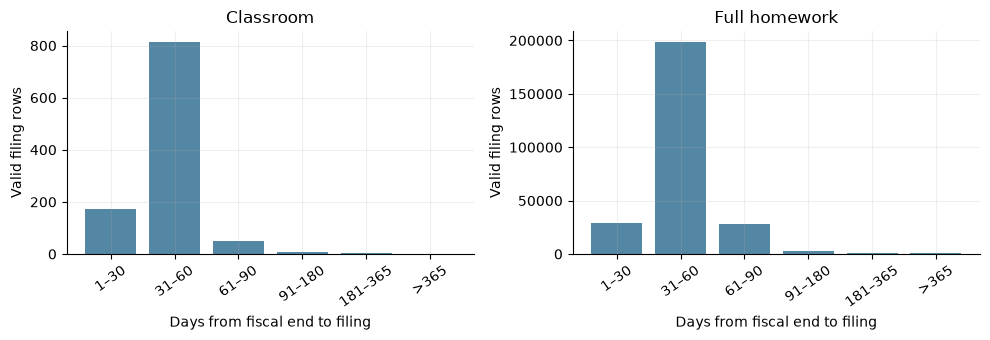

In [5]:
filing_timing_records = []
filing_lag_tables = {}

for dataset, database_path in database_paths.items():
    timing = read_query(
        database_path,
        """
        SELECT
            count(*) FILTER (WHERE filing_date IS NULL) AS missing_filing_date,
            count(*) FILTER (WHERE filing_date <= fiscal_date) AS nonpositive_lag,
            count(*) FILTER (WHERE filing_date > fiscal_date) AS valid_filing_rows,
            min(date_diff('day', fiscal_date, filing_date))
                FILTER (WHERE filing_date > fiscal_date) AS shortest_valid_lag,
            max(date_diff('day', fiscal_date, filing_date))
                FILTER (WHERE filing_date > fiscal_date) AS longest_valid_lag,
            count(*) FILTER (
                WHERE filing_date > (SELECT max(date) FROM prices)
            ) AS filings_after_price_cutoff
        FROM fundamentals
        """,
    ).iloc[0]
    filing_timing_records.append({"Dataset": dataset, **timing.to_dict()})

    filing_lags = read_query(
        database_path,
        """
        WITH valid_filings AS (
            SELECT date_diff('day', fiscal_date, filing_date) AS lag_days
            FROM fundamentals
            WHERE filing_date > fiscal_date
        ), groups AS (
            SELECT CASE
                WHEN lag_days <= 30 THEN 1
                WHEN lag_days <= 60 THEN 2
                WHEN lag_days <= 90 THEN 3
                WHEN lag_days <= 180 THEN 4
                WHEN lag_days <= 365 THEN 5
                ELSE 6
            END AS lag_group
            FROM valid_filings
        )
        SELECT lag_group, count(*) AS rows
        FROM groups
        GROUP BY lag_group
        ORDER BY lag_group
        """,
    )
    filing_lag_tables[dataset] = filing_lags
    assert filing_lags["rows"].sum() == timing["valid_filing_rows"]

filing_timing = pd.DataFrame(filing_timing_records)
display(filing_timing)

lag_labels = ["1–30", "31–60", "61–90", "91–180", "181–365", ">365"]
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, (dataset, lag_table) in zip(axes, filing_lag_tables.items()):
    counts = lag_table.set_index("lag_group")["rows"].reindex(
        range(1, 7), fill_value=0
    )
    axis.bar(lag_labels, counts, color="#5487a4")
    axis.set_title(dataset)
    axis.set_xlabel("Days from fiscal end to filing")
    axis.set_ylabel("Valid filing rows")
    axis.tick_params(axis="x", labelrotation=35)
figure.tight_layout()
plt.show()
plt.close(figure)


## Quarterly membership and ranking inputs

Use the quarter's recorded membership to choose candidates for an entry.
Membership changes apply to new purchases. Existing holdings retain their
planned holding periods. Current active status is an audit field because
it can reveal information learned after a historical trading date.

For the classroom database, count delivered members from
`universe_membership`. Its `universe_rebalances.selected_count` still
describes the full quarterly selection underlying that extract.


,Dataset,Quarters,Minimum delivered,Maximum delivered,Currently inactive stocks
0,Classroom,32,28,30,4
1,Full homework,107,1206,2000,1355


,Dataset,shares_unavailable_at_selection,selection_after_effective_start,inconsistent_availability_date,invalid_fiscal_age,invalid_rank
0,Classroom,0,0,0,0,0
1,Full homework,0,0,0,0,0


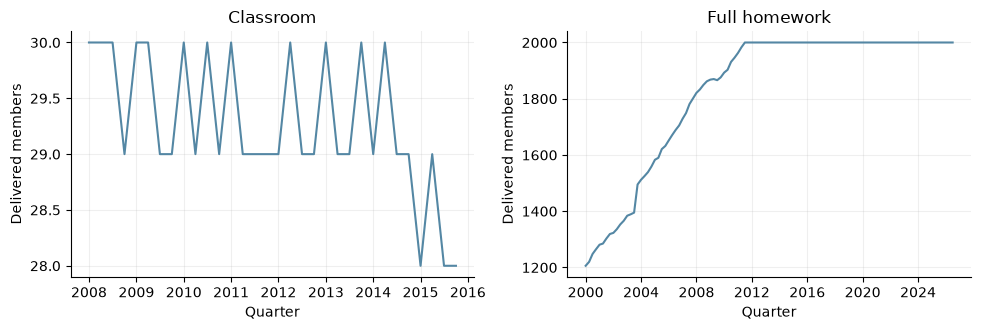

,quarter_start,symbol,universe_rank,selection_close,selection_shares,market_cap_proxy
0,2010-01-01,APDN,2,2232000.15,1.502260e+05,3.353045e+11
1,2010-01-01,TSYS,1,9.68,4.686500e+10,4.536532e+11


In [6]:
membership_records = []
membership_timing_records = []
quarterly_memberships = {}

for dataset, database_path in database_paths.items():
    quarterly_counts = read_query(
        database_path,
        """
        SELECT quarter_start, count(*) AS members
        FROM universe_membership
        GROUP BY quarter_start
        ORDER BY quarter_start
        """,
    )
    quarterly_memberships[dataset] = quarterly_counts
    inactive_count = read_query(
        database_path,
        "SELECT count(*) AS inactive FROM universe WHERE is_active_snapshot = 0",
    ).iloc[0]["inactive"]
    membership_records.append(
        {
            "Dataset": dataset,
            "Quarters": len(quarterly_counts),
            "Minimum delivered": quarterly_counts["members"].min(),
            "Maximum delivered": quarterly_counts["members"].max(),
            "Currently inactive stocks": int(inactive_count),
        }
    )

    timing_checks = read_query(
        database_path,
        """
        SELECT
            count(*) FILTER (
                WHERE shares_available_date IS NULL
                   OR shares_available_date > selection_date
            ) AS shares_unavailable_at_selection,
            count(*) FILTER (
                WHERE selection_date IS NULL OR effective_start IS NULL
                   OR selection_date >= effective_start
            ) AS selection_after_effective_start,
            count(*) FILTER (
                WHERE shares_available_date
                    <> shares_filing_date + INTERVAL '1 day'
            ) AS inconsistent_availability_date,
            count(*) FILTER (
                WHERE shares_fiscal_date > selection_date
                   OR shares_fiscal_date < selection_date - INTERVAL '18 months'
            ) AS invalid_fiscal_age,
            count(*) FILTER (
                WHERE universe_rank IS NULL
                   OR universe_rank < 1 OR universe_rank > 2000
            ) AS invalid_rank
        FROM universe_membership
        """,
    ).iloc[0]
    membership_timing_records.append(
        {"Dataset": dataset, **timing_checks.to_dict()}
    )
    assert timing_checks.eq(0).all()

membership_summary = pd.DataFrame(membership_records)
membership_timing = pd.DataFrame(membership_timing_records)
display(membership_summary)
display(membership_timing)

full_quarters = quarterly_memberships["Full homework"]
assert len(full_quarters) == manifest["quarter_count"]
assert full_quarters["members"].lt(2000).sum() == manifest["quarters_below_target"]

figure, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for axis, (dataset, quarter_table) in zip(axes, quarterly_memberships.items()):
    axis.plot(quarter_table["quarter_start"], quarter_table["members"], color="#5487a4")
    axis.set_title(dataset)
    axis.set_xlabel("Quarter")
    axis.set_ylabel("Delivered members")
figure.tight_layout()
plt.show()
plt.close(figure)

ranking_examples = read_query(
    full_database,
    """
    SELECT quarter_start, symbol, universe_rank, selection_close,
           selection_shares, market_cap_proxy
    FROM universe_candidates
    WHERE quarter_start = DATE '2010-01-01'
      AND symbol IN ('APDN', 'TSYS')
    ORDER BY symbol
    """,
)
display(ranking_examples)


The guide flags APDN's recorded price and TSYS's recorded share count
as examples requiring verification of units and corporate actions.
The table above retains those recorded inputs for inspection.
The capitalization ranking is approximate, and dated membership still
inherits the source's coverage and adjustment limitations.

## Implications for the modeling stage

- Quarantine invalid adjusted prices and off-calendar quotes before
  calculating returns. Preserve price gaps and investigate missing
  quotes affecting held positions.
- Join valid quarterly financial reports from filing date plus one day,
  applying the course's age limit to ratios. Handle missing features
  with transformations fitted within each training period.
- Select entry candidates using dated quarterly membership, including
  securities currently marked inactive. Treat static classifications
  and incomplete delisting information as source limitations.
- Align predictions made after a signal close with an entry at the next
  session's close and an exit 90 calendar days after entry, or the next
  market session. Training targets must have finished by the fit date.
- Use chronological development data to choose the model and strategy,
  then evaluate the chosen configuration over the prescribed final test.


In [7]:
for dataset, database_path in database_paths.items():
    with database_path.open("rb") as database_file:
        final_checksum = hashlib.file_digest(database_file, "sha256").hexdigest()
    assert final_checksum == original_checksums[dataset]

print("Both databases still match their original checksums.")
print("All manifest counts and key/membership checks passed.")


Both databases still match their original checksums.
All manifest counts and key/membership checks passed.
